In [21]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
# reducer
from langgraph.graph.message import add_messages
from typing import Annotated

Annotated allows you to attach additional information or metadata to a type.


It means:
- list defines the data type.
- add_messages provides additional instructions to LangGraph about how to update this field.


What is add_messages?
This is the most important part of this code.

add_messages is a message reducer in LangGraph.

Its job is to manage and update messages in the State by appending new messages instead of simply replacing the existing message list.

In [22]:
class State(TypedDict):
    messages:Annotated[list,add_messages]


In [23]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [24]:
os.environ['GROQ_API_KEY']= os.getenv('GROQ_API_KEY')

In [33]:


from langchain.chat_models import init_chat_model
llm= init_chat_model(model='openai/gpt-4.1',model_provider='groq')


In [34]:
from langchain_groq import ChatGroq
import os

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=os.getenv("GROQ_API_KEY")
)

In [35]:
def super_node(state:State)->str:
    return {'messages':[llm.invoke(state['messages'])]}

graph=StateGraph(State)
graph.add_node('super_node',super_node)

graph.add_edge(START, 'super_node')

graph.add_edge('super_node',END)

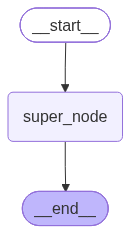

In [36]:
graph.compile()


In [37]:
graph.compile().invoke({'messages':'hi my name is mohit'})

{'messages': [HumanMessage(content='hi my name is mohit', additional_kwargs={}, response_metadata={}, id='f9d88964-0c79-47ee-85c9-c97c7d8aae0d'),
  AIMessage(content='Hello Mohit! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "hi my name is mohit". Likely they want a greeting. We should respond politely, maybe ask how can help. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 64, 'prompt_tokens': 77, 'total_tokens': 141, 'completion_time': 0.135556712, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.003445381, 'prompt_tokens_details': None, 'queue_time': 0.370007985, 'total_time': 0.139002093}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1df66-e280-7020-a6be-8e1d12317ea0-0', tool_calls=[], invalid_tool_calls=[

In [41]:
for i in  graph.compile().stream({'messages':'hi my name is mohit'}):
    print(i, end=' ')

{'super_node': {'messages': [AIMessage(content='Hello Mohit! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "hi my name is mohit". Likely they want a greeting. We should respond politely, maybe ask how can help. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 64, 'prompt_tokens': 77, 'total_tokens': 141, 'completion_time': 0.134156626, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.003096924, 'prompt_tokens_details': None, 'queue_time': 0.369969834, 'total_time': 0.13725355}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_93703442d9', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1df68-b021-74a2-8028-e1568f261361-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens': 64, 'total_tokens': 141, 'output_token_details': {'reasoning': 3